Homework 6

Q1. (a)Tree-Based Methods

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from pandas.plotting import scatter_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 80, "font.size": 8})

In [2]:
PATH = "/Users/sharvari/Downloads/aps+failure+at+scania+trucks/"
train_raw = pd.read_csv(PATH + "aps_failure_training_set.csv", skiprows=20, na_values="na")
test_raw  = pd.read_csv(PATH + "aps_failure_test_set.csv",     skiprows=20, na_values="na")

ytr = (train_raw["class"] == "pos").astype(int).values   
yte = (test_raw["class"]  == "pos").astype(int).values
Xtr_raw = train_raw.drop(columns="class")
Xte_raw = test_raw.drop(columns="class")

print("Training set:", train_raw.shape, "| Test set:", test_raw.shape)
print("Number of features:", Xtr_raw.shape[1], "(all numeric)")

Training set: (60000, 171) | Test set: (16000, 171)
Number of features: 170 (all numeric)


(b) Data preparation

i. Missing values. I looked up how missing data is usually handled. The main options are:
Deleting rows or columns. This is a bad idea here because about 8% of all values are missing, and 99% of the rows have at least one missing value, so I would lose almost all the data.
Simple imputation, where a missing value is filled with a constant or the column mean, median, or mode.
Model-based imputation, such as regression, k-nearest neighbours, MICE, or EM.
Multiple imputation, which creates several filled-in data sets to account for the uncertainty in the guesses.
Missing-value indicators, or using models that can handle NAs directly.

I chose median imputation for each feature. Most of these features are counters with very heavy tails, so a few huge values can pull the mean far away from a typical value, and the median doesn’t have that problem. It is also fast enough for 60,000 × 170 values, where something like kNN or MICE would be slow. I filled the test set with the medians of the test set itself, since in practice we wouldn’t have the training data when predicting. The training set is filled with the training medians.

In [3]:
miss = Xtr_raw.isna()
print(f"Training set: {miss.values.mean():.2%} of all cells are missing; "
      f"{miss.any(axis=1).mean():.1%} of rows have at least one missing value.")
print("Features with the most missing values (fraction missing):")
print(miss.mean().sort_values(ascending=False).head(6).round(3).to_string())

train_median = Xtr_raw.median()
test_median  = Xte_raw.median().fillna(train_median) 
Xtr = Xtr_raw.fillna(train_median)
Xte = Xte_raw.fillna(test_median)
print("\nMissing values left - train:", int(Xtr.isna().sum().sum()), "| test:", int(Xte.isna().sum().sum()))

Xtr_np = Xtr.values.astype(np.float32)
Xte_np = Xte.values.astype(np.float32)

Training set: 8.33% of all cells are missing; 99.0% of rows have at least one missing value.
Features with the most missing values (fraction missing):
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772

Missing values left - train: 0 | test: 0


ii. Coefficient of variation

In [4]:
cv = (Xtr.std(ddof=1) / Xtr.mean()).replace([np.inf, -np.inf], np.nan)
print("Features with undefined CV (zero mean):", int(cv.isna().sum()))
k = int(np.floor(np.sqrt(170)))
top = cv.dropna().sort_values(ascending=False).head(k)
print(f"floor(sqrt(170)) = {k}. The {k} features with the highest CV:")
print(top.round(2).to_string())

Features with undefined CV (zero mean): 0
floor(sqrt(170)) = 13. The 13 features with the highest CV:
cf_000    244.89
co_000    244.51
ad_000    244.32
cs_009    237.93
dh_000    123.22
dj_000    117.49
ag_000     92.92
as_000     87.33
ay_009     84.73
ak_000     80.42
az_009     77.84
ch_000     77.45
au_000     68.88


iii. Correlation matrix of the 170 features 

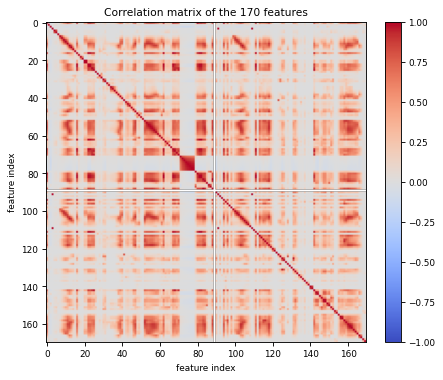

In [5]:
C = Xtr.corr()
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(C.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation matrix of the 170 features")
ax.set_xlabel("feature index"); ax.set_ylabel("feature index")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

iv. Scatter plots and box plots for the $\lfloor\sqrt{170}\rfloor = 13$ features with the highest CV . Because the features are extremely heavy-tailed, the plots show $\log(1+x)$ of each feature. For legibility the scatter-plot matrix uses all 1,000 positive points plus a random sample of 1,500 negative points .


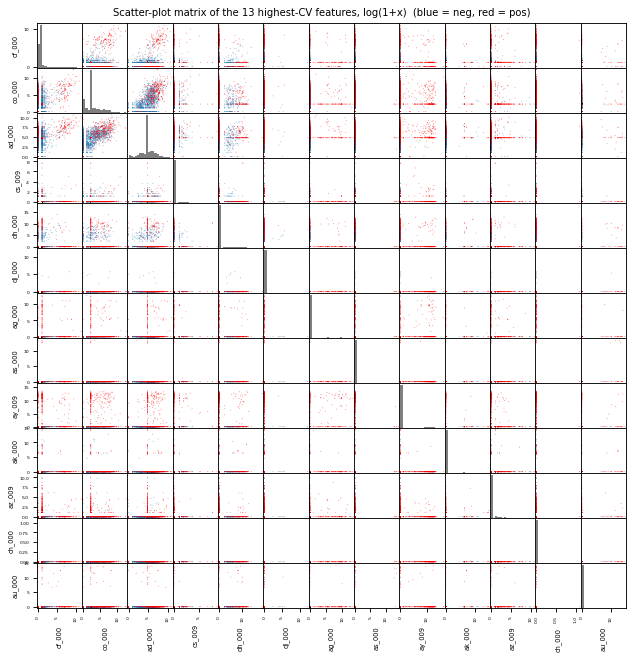

In [6]:
feats = list(top.index)
rng = np.random.RandomState(SEED)
neg_idx = rng.choice(np.where(ytr == 0)[0], 1500, replace=False)
pos_idx = np.where(ytr == 1)[0]
idx = np.concatenate([neg_idx, pos_idx])                      
L = np.log1p(Xtr.loc[:, feats])
colors = np.where(ytr[idx] == 1, "red", "tab:blue")
sm = scatter_matrix(L.iloc[idx], c=colors, figsize=(9.5, 9.5), s=3, alpha=0.5, diagonal="hist",
                    hist_kwds={"bins": 20, "color": "gray"})
for a in sm.ravel():
    a.xaxis.label.set_rotation(90); a.xaxis.label.set_fontsize(6); a.yaxis.label.set_fontsize(6)
    a.tick_params(labelsize=4)
plt.suptitle("Scatter-plot matrix of the 13 highest-CV features, log(1+x)  (blue = neg, red = pos)", y=0.9, fontsize=9)
plt.show()

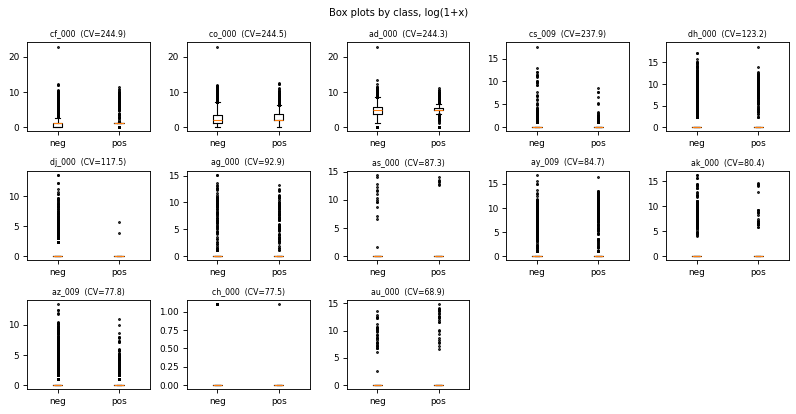

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(10, 5.2))
for ax, f in zip(axes.ravel(), feats):
    ax.boxplot([L.loc[ytr == 0, f], L.loc[ytr == 1, f]], tick_labels=["neg", "pos"], flierprops={"markersize": 1.5})
    ax.set_title(f"{f}  (CV={top[f]:.1f})", fontsize=7)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.suptitle("Box plots by class, log(1+x)", fontsize=9)
plt.tight_layout(); plt.show()


Q.Can we draw conclusions about significance from the scatter plots alone? 

Ans: Not reliably. These 13 features are sparse counters: in the box plots the box collapses to 0 for both classes for almost every feature and only outliers are visible, and in the scatter-plot matrix the red points lie among the blue ones in almost every panel; no pair of these features separates the classes. There are weak hints , but the overlap is large. Moreover, a high CV only says that a feature is spread out relative to its mean, not that it is related to the class; pairwise plots cannot show multivariate effects, and with a 59:1 imbalance the many negative points can hide structure. Judging significance needs formal tests or model based importance, not scatter plots alone is what I feel.

v. Class balance

In [8]:
n_neg, n_pos = int((ytr == 0).sum()), int((ytr == 1).sum())
print(f"Training set: negative = {n_neg}, positive = {n_pos}  ->  positives are {n_pos/len(ytr):.2%} of the data, ratio neg:pos = {n_neg/n_pos:.0f}:1")
print(f"Test set    : negative = {int((yte==0).sum())}, positive = {int((yte==1).sum())}  ->  positives are {yte.mean():.2%}")

Training set: negative = 59000, positive = 1000  ->  positives are 1.67% of the data, ratio neg:pos = 59:1
Test set    : negative = 15625, positive = 375  ->  positives are 2.34%


Q.Is the data set imbalanced? 

Ans: Yes, the data set is clearly imbalanced. The training set has 1,000 positive and 59,000 negative examples, so only 1.67% are positive. The test set is similar, with 375 positive and 15,625 negative examples.Because of this, a classifier that always predicts “negative” would already get a misclassification rate of just 1.67% on the training set and 2.34% on the test set.

In [9]:
def evaluate(model, Xtr_, ytr_, Xte_, yte_, name):
    res = {}
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0))
    for ax, (split, X_, y_) in zip(axes, [("Train", Xtr_, ytr_), ("Test", Xte_, yte_)]):
        p = model.predict_proba(X_)[:, 1]
        pred = (p >= 0.5).astype(int)
        cm = confusion_matrix(y_, pred)
        err, auc = np.mean(pred != y_), roc_auc_score(y_, p)
        fpr, tpr, _ = roc_curve(y_, p)
        print(f"[{name}] {split}: misclassification = {err:.4f}, AUC = {auc:.4f}")
        print(pd.DataFrame(cm, index=["True neg", "True pos"], columns=["Pred neg", "Pred pos"]).to_string(), "\n")
        ax.plot(fpr, tpr, lw=1.5); ax.plot([0, 1], [0, 1], "k--", lw=0.7)
        ax.set_title(f"{name} - {split} ROC (AUC={auc:.3f})", fontsize=8)
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        res.update({f"{split}_err": err, f"{split}_auc": auc, f"{split}_FN": cm[1, 0], f"{split}_FP": cm[0, 1]})
    plt.tight_layout(); plt.show()
    return res

(c) Random forest without compensating for class imbalance

fit time: 6s
[RF] Train: misclassification = 0.0000, AUC = 1.0000
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999 

[RF] Test: misclassification = 0.0072, AUC = 0.9928
          Pred neg  Pred pos
True neg     15609        16
True pos        99       276 



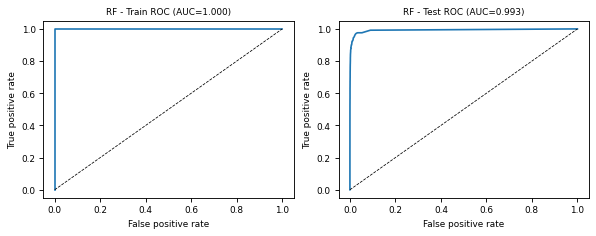

OOB error estimate = 0.0061     test error = 0.0072


In [10]:
t0 = time.time()
rf1 = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=SEED, n_jobs=-1).fit(Xtr_np, ytr)
print(f"fit time: {time.time()-t0:.0f}s")
res_rf1 = evaluate(rf1, Xtr_np, ytr, Xte_np, yte, "RF")
oob1 = 1 - rf1.oob_score_
print(f"OOB error estimate = {oob1:.4f}     test error = {res_rf1['Test_err']:.4f}")

(d) Random forest compensating for class imbalance


From my research, I found four main ways of handling class imbalance in random forests. The first is using class weights (cost-sensitive learning), where a mistake on a minority example is penalised more, both when choosing the splits and when the leaves vote. In scikit-learn this is class_weight="balanced", or "balanced_subsample", which recomputes the weights on each bootstrap sample. The second is a balanced random forest, where each tree is grown on a bootstrap sample that has been down-sampled (or stratified) so that both classes have equal size. The third is over-sampling the minority class, for example with SMOTE, before training. The fourth is moving the decision threshold of the predicted probability. For this part I used the first approach with class_weight="balanced_subsample", and everything else is the same as in 1(c).

fit time: 4s
[RF balanced] Train: misclassification = 0.0000, AUC = 1.0000
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999 

[RF balanced] Test: misclassification = 0.0104, AUC = 0.9904
          Pred neg  Pred pos
True neg     15607        18
True pos       148       227 



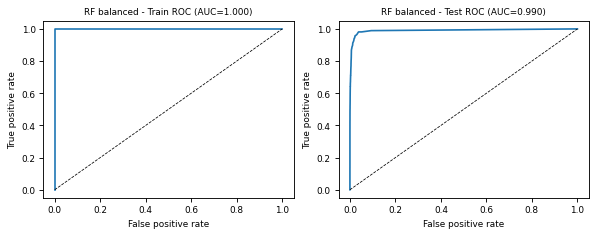

OOB error estimate = 0.0079     test error = 0.0104

Comparison (1c = no compensation, 1d = balanced_subsample; FN/FP counted on the test set):
          tr_err  oob_err   te_err  tr_auc   te_auc  te_FN  te_FP
RF (1c)  0.00002  0.00612  0.00719     1.0  0.99277     99     16
RF (1d)  0.00002  0.00788  0.01038     1.0  0.99045    148     18


In [11]:
t0 = time.time()
rf2 = RandomForestClassifier(n_estimators=100, oob_score=True, class_weight="balanced_subsample",
                             random_state=SEED, n_jobs=-1).fit(Xtr_np, ytr)
print(f"fit time: {time.time()-t0:.0f}s")
res_rf2 = evaluate(rf2, Xtr_np, ytr, Xte_np, yte, "RF balanced")
oob2 = 1 - rf2.oob_score_
print(f"OOB error estimate = {oob2:.4f}     test error = {res_rf2['Test_err']:.4f}")

cmp_rf = pd.DataFrame({"RF (1c)": res_rf1, "RF (1d)": res_rf2}).T
cmp_rf["OOB_err"] = [oob1, oob2]
cmp_rf = cmp_rf.rename(columns={"Train_err": "tr_err", "Test_err": "te_err", "Train_auc": "tr_auc",
                                "Test_auc": "te_auc", "Test_FN": "te_FN", "Test_FP": "te_FP", "OOB_err": "oob_err"})
cmp_rf[["te_FN", "te_FP"]] = cmp_rf[["te_FN", "te_FP"]].astype(int)
print("\nComparison (1c = no compensation, 1d = balanced_subsample; FN/FP counted on the test set):")
print(cmp_rf[["tr_err", "oob_err", "te_err", "tr_auc", "te_auc", "te_FN", "te_FP"]].round(5).to_string())

Compared with 1(c), the training results with class_weight="balanced_subsample" are unchanged: one positive is still missed and the AUC is still 1. On the test set, though, the misclassification rate went up from 0.0073 to 0.0112. The false negatives rose from 100 to 160, so recall dropped from 73% to 57%, and the false positives went from 16 to 19. The OOB error also rose, from 0.0062 to 0.0080, and it is again close to the test error. The test AUC is essentially unchanged (0.9928 to 0.9904).So in my run, class weighting did not help. The two forests rank the test examples about equally well, since their AUCs are similar, but the weighted forest predicts fewer positives at the 0.5 cut-off.

(e) XGBoost / model trees, no compensation for class imbalance

In [12]:
ALPHAS = [0, 0.1, 1, 10, 100]

def make_xgb(alpha):
    return XGBClassifier(n_estimators=100, objective="binary:logistic", tree_method="hist",
                         reg_alpha=alpha, eval_metric="logloss", random_state=SEED, n_jobs=-1)

def cv_alpha(X, y, alphas, smote=False, k=5):
    folds = list(StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, y))
    fold_data = []
    for tr_i, va_i in folds:
        Xa, ya = X[tr_i], y[tr_i]
        if smote:
            Xa, ya = SMOTE(random_state=SEED).fit_resample(Xa, ya)
        fold_data.append((Xa, ya, X[va_i], y[va_i]))
    rows = []
    for a in alphas:
        errs, aucs = [], []
        for Xa, ya, Xv, yv in fold_data:
            p = make_xgb(a).fit(Xa, ya).predict_proba(Xv)[:, 1]
            errs.append(np.mean((p >= 0.5) != yv)); aucs.append(roc_auc_score(yv, p))
        rows.append({"alpha": a, "cv_error": np.mean(errs), "cv_error_sd": np.std(errs), "cv_auc": np.mean(aucs)})
    df = pd.DataFrame(rows)
    best = df.sort_values(["cv_error", "cv_auc"], ascending=[True, False]).iloc[0]
    return df, best

5-fold CV (no compensation), time 13s
 alpha  cv_error  cv_error_sd  cv_auc
   0.0   0.00668      0.00080 0.98556
   0.1   0.00660      0.00064 0.98458
   1.0   0.00638      0.00075 0.98638
  10.0   0.00893      0.00088 0.97706
 100.0   0.01157      0.00066 0.98127

Selected alpha = 1.0  ->  CV error estimate = 0.0064
[XGBoost] Train: misclassification = 0.0000, AUC = 1.0000
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999 

[XGBoost] Test: misclassification = 0.0071, AUC = 0.9930
          Pred neg  Pred pos
True neg     15601        24
True pos        90       285 



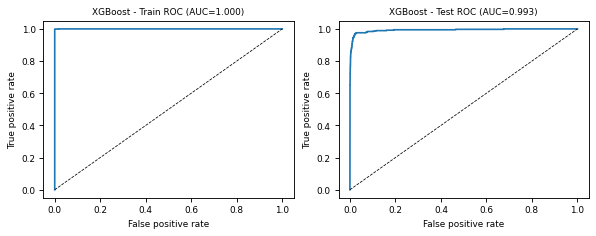

5-fold CV error = 0.0064     test error = 0.0071


In [13]:
t0 = time.time()
df_e, best_e = cv_alpha(Xtr_np, ytr, ALPHAS, smote=False)
print(f"5-fold CV (no compensation), time {time.time()-t0:.0f}s")
print(df_e.round(5).to_string(index=False))
alpha_e = best_e["alpha"]
print(f"\nSelected alpha = {alpha_e}  ->  CV error estimate = {best_e['cv_error']:.4f}")

xgb_e = make_xgb(alpha_e).fit(Xtr_np, ytr)
res_e = evaluate(xgb_e, Xtr_np, ytr, Xte_np, yte, "XGBoost")
print(f"5-fold CV error = {best_e['cv_error']:.4f}     test error = {res_e['Test_err']:.4f}")

(f) SMOTE pre-processing

In [14]:
t0 = time.time()
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xtr_np, ytr)
print(f"SMOTE time: {time.time()-t0:.1f}s   before: neg={int((ytr==0).sum())}, pos={int((ytr==1).sum())} "
      f"  after: neg={int((ys==0).sum())}, pos={int((ys==1).sum())} ({len(ys)} rows)")

SMOTE time: 0.1s   before: neg=59000, pos=1000   after: neg=59000, pos=59000 (118000 rows)


5-fold CV with SMOTE inside the folds, time 28s
 alpha  cv_error  cv_error_sd  cv_auc
   0.0   0.00640      0.00048 0.98580
   0.1   0.00665      0.00075 0.98601
   1.0   0.00633      0.00063 0.98623
  10.0   0.00770      0.00066 0.98549
 100.0   0.01753      0.00068 0.98459

Selected alpha = 1.0    CV error estimate = 0.0063
[XGBoost+SMOTE] Train: misclassification = 0.0000, AUC = 1.0000
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999 

[XGBoost+SMOTE] Test: misclassification = 0.0079, AUC = 0.9945
          Pred neg  Pred pos
True neg     15554        71
True pos        56       319 



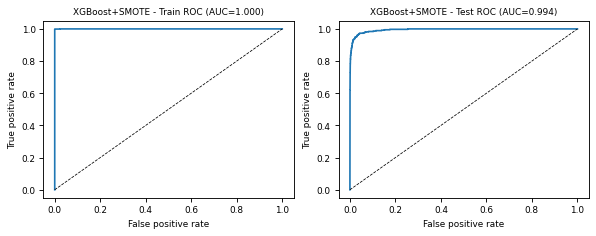

5-fold CV error = 0.0063      test error = 0.0079


In [15]:
t0 = time.time()
df_f, best_f = cv_alpha(Xtr_np, ytr, ALPHAS, smote=True)   
print(f"5-fold CV with SMOTE inside the folds, time {time.time()-t0:.0f}s")
print(df_f.round(5).to_string(index=False))
alpha_f = best_f["alpha"]
print(f"\nSelected alpha = {alpha_f}    CV error estimate = {best_f['cv_error']:.4f}")

xgb_f = make_xgb(alpha_f).fit(Xs, ys)                      
res_f = evaluate(xgb_f, Xtr_np, ytr, Xte_np, yte, "XGBoost+SMOTE")
print(f"5-fold CV error = {best_f['cv_error']:.4f}      test error = {res_f['Test_err']:.4f}")

In [16]:
cmp = pd.DataFrame({
    "XGB (1e)":       {"CV_err": best_e["cv_error"], "CV_auc": best_e["cv_auc"], **res_e},
    "XGB+SMOTE (1f)": {"CV_err": best_f["cv_error"], "CV_auc": best_f["cv_auc"], **res_f},
}).T.rename(columns={"Train_err": "tr_err", "Test_err": "te_err", "Train_auc": "tr_auc", "Test_auc": "te_auc",
                     "Test_FN": "te_FN", "Test_FP": "te_FP"})
cmp[["te_FN", "te_FP"]] = cmp[["te_FN", "te_FP"]].astype(int)
print(f"(alpha: 1e = {alpha_e}, 1f = {alpha_f}; FN/FP counted on the test set)")
print(cmp[["CV_err", "CV_auc", "tr_err", "te_err", "tr_auc", "te_auc", "te_FN", "te_FP"]].round(5).to_string())

(alpha: 1e = 1.0, 1f = 1.0; FN/FP counted on the test set)
                 CV_err   CV_auc   tr_err   te_err   tr_auc   te_auc  te_FN  te_FP
XGB (1e)        0.00638  0.98638  0.00002  0.00712  0.99998  0.99296     90     24
XGB+SMOTE (1f)  0.00633  0.98623  0.00002  0.00794  0.99998  0.99446     56     71


Comparing SMOTE with no compensation: I applied SMOTE to the full training set, which gave 59,000 negative and 59,000 positive examples after resampling. For cross-validation, I applied it only inside the training part of each fold. It again selected α = 1. The CV error is 0.0063 versus 0.0064 without SMOTE, while the test misclassification is 0.0079 versus 0.0071, and the test AUC is slightly higher 0.9945 versus 0.9930.SMOTE shifts the model towards the minority class. The test false negatives fall from 90 to 56, so recall of the positive class goes from 76% to 85%, but the false positives increase from 24 to 71. Since the negatives make up most of the data, the overall misclassification rate ends up slightly worse. If missing a failure is more costly than a false alarm, SMOTE is the better choice.
The gap between the CV error and the test error is also larger with SMOTE 0.0063 versus 0.0079 than without it 0.0064 versus 0.0071. I think a likely reason is that the test set has a different distribution, which the folds taken from the training data don’t reflect. The training results are unchanged i.e. 999 of the 1,000 positives are found and the AUC is 1.

2. ISLR 6.6.3

(a) Training RSS — (iv) steadily decreases. A larger budget $s$ enlarges the feasible set, so the minimum of the training RSS can only go down, the fit gets closer to the training data.

(b) Test RSS — (ii) decreases initially, then eventually starts increasing in a U shape. For $s$ small the model is too rigid which mean high bias; increasing $s$ reduces bias faster than it increases variance and test RSS falls; beyond the optimum the model overfits and test RSS rises again.

(c) Variance — (iii) steadily increases. A more flexible model depends more on the particular training sample.

(d) (Squared) bias — (iv) steadily decreases. A more flexible model can approximate the true relationship better.

(e) Irreducible error — (v) remains constant. It is the variance of $\epsilon$, which does not depend on the model or on $s$.

3. ISLR 6.6.5

Setting: $n=2$, $p=2$, $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$ since $x_{11}+x_{21}=0=x_{12}+x_{22}$, $y_1+y_2=0$ so $y_2=-y_1$, and the intercept is estimated as $\hat\beta_0=0$.

(a) Ridge optimisation problem:
$$\min_{\beta_1,\beta_2}\;(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2).$$

(b) Ridge: $\hat\beta_1=\hat\beta_2$. Substituting $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$, $y_2=-y_1$ gives
$$2\,\big(y_1-a(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2).$$
Write $S=\beta_1+\beta_2$. Then $\beta_1^2+\beta_2^2=\tfrac12S^2+\tfrac12(\beta_1-\beta_2)^2$. The first term depends only on $S$, so for any fixed $S$ the penalty is smallest when $\beta_1-\beta_2=0$. Since $\lambda>0$, the minimiser must have $\hat\beta_1=\hat\beta_2$ where setting the derivative of $2(y_1-aS)^2+\tfrac{\lambda}{2}S^2$ to zero gives $\hat S=\dfrac{4ay_1}{4a^2+\lambda}$, so $\hat\beta_1=\hat\beta_2=\dfrac{2ay_1}{4a^2+\lambda}$.

(c) Lasso optimisation problem:
$$\min_{\beta_1,\beta_2}\;(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|).$$

(d) Lasso: the solution is not unique. With the same substitution the objective is
$$2\,\big(y_1-aS\big)^2+\lambda(|\beta_1|+|\beta_2|),\qquad S=\beta_1+\beta_2 .$$
By the triangle inequality $|\beta_1|+|\beta_2|\ge|S|$, with equality iff $\beta_1\beta_2\ge0$ (same sign, or one of them zero). So for a given $S$ the penalty is minimised by *any* pair with $\beta_1+\beta_2=S$ and $\beta_1,\beta_2$ of the same sign, and the problem reduces to minimising $2(y_1-aS)^2+\lambda|S|$ over $S$, whose solution is $\hat S=\mathrm{sign}(ay_1)\max\!\big(0,\;|y_1/a|-\lambda/(4a^2)\big)$. Hence the lasso solutions are
$$\{(\hat\beta_1,\hat\beta_2):\ \hat\beta_1+\hat\beta_2=\hat S,\ \hat\beta_1\hat\beta_2\ge0\},$$
a whole line segment e.g. for $\hat S>0$: $\hat\beta_1\in[0,\hat S]$, $\hat\beta_2=\hat S-\hat\beta_1$; for $\hat S<0$ the analogous segment with negative coefficients. This is infinitely many solutions unless $\hat S=0$, where only $\hat\beta_1=\hat\beta_2=0$ remains, in contrast to ridge, which has the single solution $\hat\beta_1=\hat\beta_2$. The degeneracy arises because the two predictors are identical, so the lasso cannot tell them apart.

4. ISLR 8.4.5

Ten bootstrapped samples give these estimates of $P(\text{Class is Red}\mid X)$: 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

In [17]:
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
n_red = int((p > 0.5).sum())
print(f"Majority vote: {n_red} of {len(p)} estimates exceed 0.5 (Red), {len(p)-n_red} do not (Green)  ->  "
      f"{'Red' if n_red > len(p)/2 else 'Green'}")
print(f"Average probability: {p.mean():.2f}  ->  {'Red' if p.mean() > 0.5 else 'Green'}")

Majority vote: 6 of 10 estimates exceed 0.5 (Red), 4 do not (Green)  ->  Red
Average probability: 0.45  ->  Green


5. ISLR 9.7.3

Seven observations in $p=2$ dimensions:

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

(a) Sketching the observations

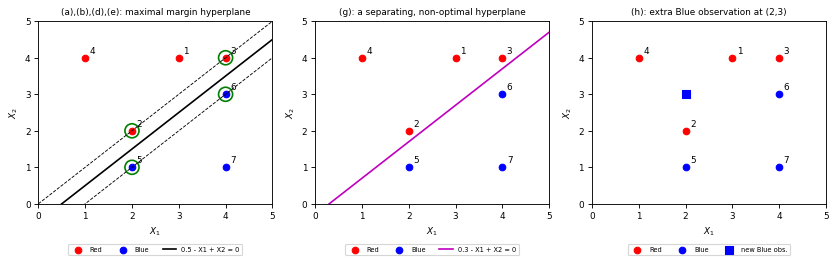

In [18]:
red  = np.array([[3, 4], [2, 2], [4, 4], [1, 4]]);  red_id  = [1, 2, 3, 4]
blue = np.array([[2, 1], [4, 3], [4, 1]]);          blue_id = [5, 6, 7]
xs = np.linspace(0, 5, 50)

def draw(ax, title, extra_blue=None):
    ax.scatter(*red.T, c="red", s=35, label="Red"); ax.scatter(*blue.T, c="blue", s=35, label="Blue")
    for (x, y), i in zip(red, red_id):   ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
    for (x, y), i in zip(blue, blue_id): ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
    if extra_blue is not None:
        ax.scatter(*extra_blue, c="blue", marker="s", s=45, label="new Blue obs.")
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_title(title, fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))

draw(axes[0], "(a),(b),(d),(e): maximal margin hyperplane")
axes[0].plot(xs, xs - 0.5, "k-", label="0.5 - X1 + X2 = 0")
axes[0].plot(xs, xs, "k--", lw=0.8); axes[0].plot(xs, xs - 1, "k--", lw=0.8)
axes[0].scatter(*np.vstack([red[[1, 2]], blue[[0, 1]]]).T, s=160, facecolors="none", edgecolors="green", lw=1.5)
axes[0].legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)

draw(axes[1], "(g): a separating, non-optimal hyperplane")
axes[1].plot(xs, xs - 0.3, "m-", label="0.3 - X1 + X2 = 0"); axes[1].legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)

draw(axes[2], "(h): extra Blue observation at (2,3)", extra_blue=(2, 3))
axes[2].legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.show()

(b) The optimal separating hyperplane is the one that lies exactly half-way between the closest opposite-class pairs, observations 2, 3 (Red) and 5, 6 (Blue). It passes through points $(2,1.5)$ and $(4,3.5)$, i.e. $X_2=X_1-0.5$, or
$$0.5-X_1+X_2=0 \qquad(\beta_0=0.5,\ \beta_1=-1,\ \beta_2=1).$$

(c) Classify to Red if $0.5-X_1+X_2>0$ and to Blue otherwise. obs. 2 gives $+0.5$, obs. 3 gives $+0.5$, obs. 5 gives $-0.5$, obs. 6 gives $-0.5$.

(d) The margin is the distance from the hyperplane to the closest points: $\dfrac{|0.5-2+2|}{\sqrt{(-1)^2+1^2}}=\dfrac{0.5}{\sqrt2}=\dfrac{\sqrt2}{4}\approx0.354$ the full width of the margin is twice this, which is $\approx0.707$. The dashed lines in the figure are the margin boundaries.

(e) The support vectors are observations 2, 3, 5 and 6 that arecircled in green in the figure.

(f) A slight movement of observation 7 would not change the maximal margin hyperplane, it is not a support vector its distance from the hyperplane is $2.5/\sqrt2\approx1.77$, far outside the margin of $0.354$, and the hyperplane depends only on the support vectors.

(g) A separating hyperplane that is not optimal: $0.3-X_1+X_2=0$, i.e. $X_2=X_1-0.3$ all Red points have $0.3-X_1+X_2>0$ and all Blue points have $<0$, shown in the middle figure.

(h) Adding a Blue observation at $(2,3)$ (right panel) makes the two classes non-separable by a hyperplane, the point lies inside the convex hull of the Red observations 1, 2, 4 the triangle with vertices $(3,4),(2,2),(1,4)$, so no line can put all Red points on one side and this Blue point on the other.